In [11]:
#PROYECTO FINAL - CIENCIA COMPUTACIONAL
#PARTE F - INFERENCIA ESTADISTICA

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

C1 = 2028596201
C2 = 2035384971
S = C1 + C2  # S = 4063981172

#Parámetros que dependen de s
tau = 180 + 10 * (S % 9)
epsilon = 0.01 * (1 + S % 3)
confianza = [0.90, 0.95, 0.99][S % 3]
alpha = 1 - confianza
N = 10 + (S % 11)

#Semilla aleatoria
rng = np.random.default_rng(S)
print(f"S={S}, tau={tau} ms, epsilon={epsilon}, 1-alpha={confianza}, N={N}")


S=4063981172, tau=230 ms, epsilon=0.03, 1-alpha=0.99, N=19


In [10]:
#Carga De Datos
from google.colab import files
import zipfile

subido = files.upload()
nombre_zip = list(subido.keys())[0]
with zipfile.ZipFile(nombre_zip) as z:
    z.extract("solicitudes.csv")
    z.extract("monitoreo.csv")
solicitudes = pd.read_csv("solicitudes.csv")
monitoreo = pd.read_csv("monitoreo.csv")

print("solicitudes:", solicitudes.shape)
print("monitoreo:  ", monitoreo.shape)
display(solicitudes.head())
solicitudes.info()
display(solicitudes.describe())


Saving Archivos Proyecto Final Grupo 4 - G03-20261122.zip to Archivos Proyecto Final Grupo 4 - G03-20261122 (1).zip
solicitudes: (32472, 10)
monitoreo:   (6000, 4)


,id_solicitud,t_llegada_s,tam_kb,cache_hit,version,red_ms,gpu_ms,latencia_ms,intentos,exito
0,1,0.0060,108.47,0,B,25.29,8.37,33.65,1,1
1,2,0.1270,629.91,0,A,27.24,149.39,176.63,1,1
2,3,0.1612,179.72,0,B,24.69,49.68,74.37,1,1
3,4,0.1690,429.34,0,B,21.15,66.91,129.94,2,1
4,5,0.1867,229.65,0,B,33.99,33.09,156.75,1,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32472 entries, 0 to 32471
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id_solicitud  32472 non-null  int64  
 1   t_llegada_s   32472 non-null  float64
 2   tam_kb        32472 non-null  float64
 3   cache_hit     32472 non-null  int64  
 4   version       32472 non-null  object 
 5   red_ms        32440 non-null  float64
 6   gpu_ms        32440 non-null  float64
 7   latencia_ms   32472 non-null  float64
 8   intentos      32472 non-null  int64  
 9   exito         32472 non-null  int64  
dtypes: float64(5), int64(4), object(1)
memory usage: 2.5+ MB


,id_solicitud,t_llegada_s,tam_kb,cache_hit,red_ms,gpu_ms,latencia_ms,intentos,exito
count,32472.000000,32472.000000,3.247200e+04,32472.000000,32440.000000,32440.000000,32472.000000,32472.000000,32472.000000
mean,16185.424889,577.057260,5.859546e+02,0.350025,26.418489,32.499267,97.097913,1.288926,0.982539
std,9346.473559,314.574098,1.131483e+04,0.476985,3.903051,40.983941,120.074210,0.568850,0.130984
min,1.000000,0.006000,1.600000e-01,0.000000,9.410000,0.000000,-1.000000,1.000000,0.000000
25%,8090.750000,372.064800,1.161925e+02,0.000000,23.800000,0.000000,28.487500,1.000000,1.000000
50%,16184.500000,529.790850,2.014700e+02,0.000000,26.400000,21.410000,55.010000,1.000000,1.000000
75%,24279.250000,822.684750,3.226925e+02,1.000000,29.050000,48.010000,106.935000,1.000000,1.000000
max,32375.000000,1199.887500,1.020774e+06,1.000000,41.690000,604.470000,1114.310000,3.000000,1.000000


In [ ]:
# PUNTO DE ENLACE CON LA PARTE A (A1 limpieza + A2 régimen estable)
# Todo el código de la Parte F usa df_est.

T_INI_ANOM, T_FIN_ANOM = 397, 577   # tramo inestable [397, 577) s (A2)

def limpiar_datos(df_crudo):
    """A1: auditoría y tratamiento de inconsistencias."""
    d = df_crudo.drop_duplicates().copy()                 # 97 duplicados exactos

    mask_bytes = d["tam_kb"] > 5000                     # 48 filas en bytes, no KB
    d.loc[mask_bytes, "tam_kb"] = d.loc[mask_bytes, "tam_kb"] / 1024

    d = d[d["latencia_ms"] > 0].copy()                    # 97 latencias centinela (-1)

    # Faltantes: con caché se reconstruyen; sin caché se excluyen
    cache = d["cache_hit"] == 1
    d.loc[cache & d["gpu_ms"].isna(), "gpu_ms"] = 0
    falta_red = cache & d["red_ms"].isna()
    d.loc[falta_red, "red_ms"] = d.loc[falta_red, "latencia_ms"]
    d = d[~(d["red_ms"].isna() | d["gpu_ms"].isna())].copy()

    # Cota física: L >= red + gpu (cola >= 0), con tolerancia de redondeo
    d = d[d["latencia_ms"] >= d["red_ms"] + d["gpu_ms"] - 0.02].copy()
    return d.reset_index(drop=True)

def preparar_datos(df_crudo):
    d = limpiar_datos(df_crudo)
    # A2: régimen estable = antes y después del tramo anómalo
    d = d[(d["t_llegada_s"] < T_INI_ANOM) | (d["t_llegada_s"] >= T_FIN_ANOM)].copy()
    d = d.reset_index(drop=True)
    # Variables derivadas para la Parte F
    d["viola_tau"] = (d["latencia_ms"] > tau).astype(int)
    d["reintento"] = (d["intentos"] > 1).astype(int)
    d["no_cache"] = (d["cache_hit"] == 0)
    return d

df_est = preparar_datos(solicitudes)
print("Filas en df_est:", len(df_est))   # debe dar 22009
print(df_est["version"].value_counts())


Filas en df_est: 22009
version
B    11060
A    10949
Name: count, dtype: int64


**F1.**

F1. Distribución muestral de la media de la latencia

In [ ]:
#Paso 1: población para la simulación = latencias del régimen estable
poblacion = df_est["latencia_ms"].to_numpy()

mu_pob = poblacion.mean()          # media poblacional "verdadera"
sd_pob = poblacion.std(ddof=0)     # desviación poblacional
print(f"N = {len(poblacion)} | Media = {mu_pob:.2f} ms | DE = {sd_pob:.2f} ms")
print(f"Asimetría = {stats.skew(poblacion):.2f} | Curtosis en exceso = {stats.kurtosis(poblacion):.2f}")

N = 22009 | Media = 63.19 ms | DE = 46.00 ms
Asimetría = 2.10 | Curtosis en exceso = 7.37


In [ ]:
#Paso 2: distribución muestral de la media
R = 10_000                       # muestras por cada tamaño n
ns_f1 = [5, 30, 200, 2000]

medias = {}                      # medias[n] = las R medias muestrales
for n in ns_f1:
    muestras = rng.choice(poblacion, size=(R, n), replace=True)  # R muestras de tamaño n
    medias[n] = muestras.mean(axis=1)                            # media de cada muestra

# Descripción de cada distribución muestral
resumen_f1 = pd.DataFrame({
    n: {"media de las medias": m.mean(),
        "DE observada": m.std(ddof=1),
        "DE teórica (σ/√n)": sd_pob / np.sqrt(n),
        "asimetría": stats.skew(m),
        "curtosis (exceso)": stats.kurtosis(m)}
    for n, m in medias.items()
}).T
display(resumen_f1.round(3))

,media de las medias,DE observada,DE teórica (σ/√n),asimetría,curtosis (exceso)
5,63.202,20.557,20.574,0.949,1.471
30,63.167,8.381,8.399,0.416,0.219
200,63.189,3.253,3.253,0.156,0.005
2000,63.180,1.023,1.029,0.032,0.001


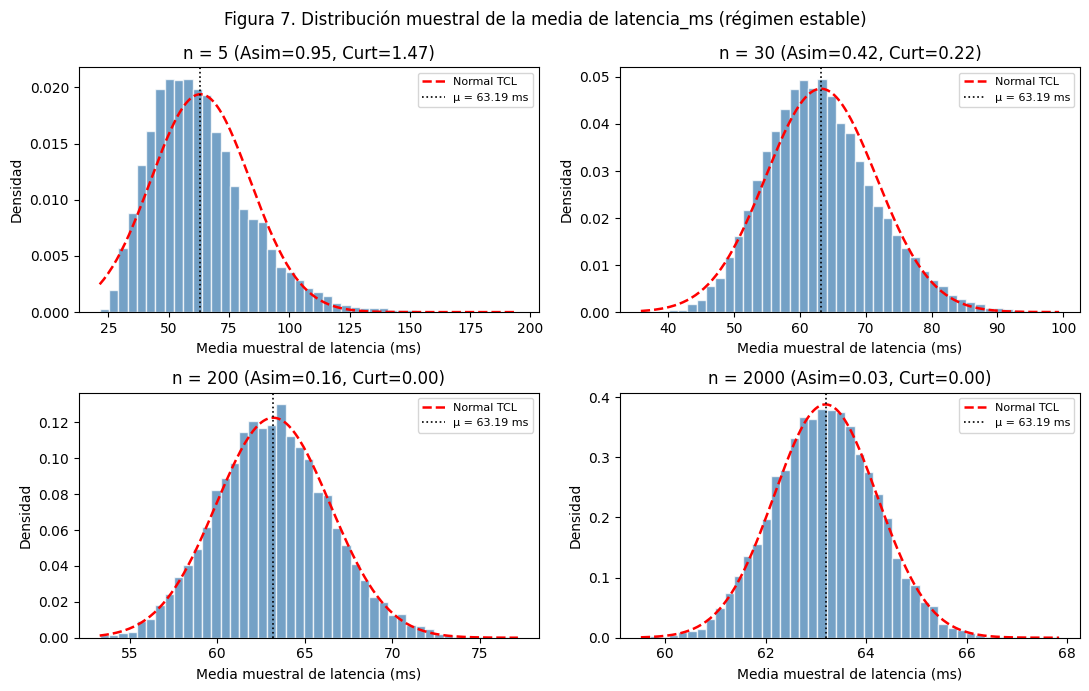

,n,cobertura
0,5,0.8762
5,30,0.9623
9,50,0.9732
19,100,0.9806
24,150,0.9847
29,200,0.9862
34,250,0.9873
39,300,0.9864


Meta de cobertura: >= 0.98 (1 - alpha - 0.01)
Menor n que alcanza la meta: n = 80


In [ ]:
# Paso 3: Figura 7 — Evolución de la distribución muestral de la media
# Creamos una cuadrícula de 2x2 paneles (uno para cada tamaño de muestra n)
fig, ejes = plt.subplots(2, 2, figsize=(11, 7))

# Recorremos cada panel junto con su tamaño n correspondiente
for eje, n in zip(ejes.ravel(), ns_f1):
    m = medias[n]                                      # las R = 10,000 medias simuladas para este n

    # Dibujamos el histograma normalizado (densidad) de las medias muestrales
    eje.hist(m, bins=45, density=True, alpha=0.75, color="steelblue", edgecolor="white")

    # Calculamos la curva Normal teórica que predice el Teorema Central del Límite (TCL)
    x_grid = np.linspace(m.min(), m.max(), 200)        # puntos en el eje x para trazar la curva
    ee_teorico = sd_pob / np.sqrt(n)                   # error estándar teórico: σ / √n
    eje.plot(x_grid, stats.norm.pdf(x_grid, loc=mu_pob, scale=ee_teorico),
             "r--", lw=1.8, label="Normal TCL")

    # Línea vertical punteada marcando la media poblacional verdadera
    eje.axvline(mu_pob, color="k", linestyle=":", lw=1.2, label=f"μ = {mu_pob:.2f} ms")

    # Títulos y etiquetas del panel mostrando asimetría y curtosis de cada n
    eje.set_title(f"n = {n} (Asim={stats.skew(m):.2f}, Curt={stats.kurtosis(m):.2f})")
    eje.set_xlabel("Media muestral de latencia (ms)")
    eje.set_ylabel("Densidad")
    eje.legend(fontsize=8)

# Título general de la Figura 7 y ajuste para que no se encimen los textos
fig.suptitle("Figura 7. Distribución muestral de la media de latencia_ms (régimen estable)", fontsize=12)
plt.tight_layout()
plt.show()

# Paso 4: Buscar el menor n con cobertura efectiva >= (1 - alpha) - 0.01
z_crit = stats.norm.ppf(1 - alpha / 2)                 # valor crítico normal z (para 99% es ~2.576)
meta_cobertura = confianza - 0.01                      # cobertura mínima exigida: 0.99 - 0.01 = 0.98

# Probamos tamaños de muestra crecientes: de 5 en 5 hasta 100, y de 10 en 10 hasta 400
ns_busqueda = list(range(5, 101, 5)) + list(range(110, 401, 10))
coberturas_f1 = []
menor_n_valido = None

for n_cand in ns_busqueda:
    # Extraemos R muestras de tamaño n_cand de la población
    m = rng.choice(poblacion, size=(R, n_cand), replace=True)
    x_bar = m.mean(axis=1)                             # media de cada muestra
    s_muestra = m.std(axis=1, ddof=1)                  # desviación estándar muestral (con n-1)

    # Construimos el intervalo con aproximación normal: x_bar ± z * (s / √n)
    margen = z_crit * (s_muestra / np.sqrt(n_cand))
    acierto = (x_bar - margen <= mu_pob) & (mu_pob <= x_bar + margen)  # ¿atrapó a mu_pob?
    cob = acierto.mean()                               # proporción de intervalos que aciertan

    coberturas_f1.append({"n": n_cand, "cobertura": cob})

    # Guardamos el primer n que alcanza o supera la meta de cobertura (0.98)
    if cob >= meta_cobertura and menor_n_valido is None:
        menor_n_valido = n_cand

# Mostramos una tabla resumen con tamaños clave y el menor n encontrado
df_cob_f1 = pd.DataFrame(coberturas_f1)
display(df_cob_f1[df_cob_f1["n"].isin([5, 30, 50, 100, 150, 200, 250, 300])].round(4))
print(f"Meta de cobertura: >= {meta_cobertura:.2f} (1 - alpha - 0.01)")
print(f"Menor n que alcanza la meta: n = {menor_n_valido}")

**F2.**

F2. Intervalo de confianza para la latencia media

In [ ]:
# Paso 1: Intervalo de confianza clásico (t de Student) sobre el régimen estable
datos_f2 = df_est["latencia_ms"].to_numpy()              # las 22 009 latencias del régimen estable
n_f2 = len(datos_f2)                                     # tamaño de muestra

media_obs = np.mean(datos_f2)                            # media muestral observada (ms)
sd_obs = np.std(datos_f2, ddof=1)                        # desviación estándar muestral (ddof=1)
ee_obs = sd_obs / np.sqrt(n_f2)                          # error estándar clásico: s / √n

# Valor crítico t de Student con n - 1 grados de libertad para confianza 1 - alpha = 0.99
t_crit = stats.t.ppf(1 - alpha / 2, df=n_f2 - 1)
ic_clasico = (media_obs - t_crit * ee_obs, media_obs + t_crit * ee_obs)
ancho_clasico = ic_clasico[1] - ic_clasico[0]            # amplitud total del intervalo clásico

print(f"Media = {media_obs:.4f} ms | DE = {sd_obs:.4f} ms | EE clásico = {ee_obs:.4f} ms")
print(f"IC clásico t ({confianza:.0%}): [{ic_clasico[0]:.4f}, {ic_clasico[1]:.4f}] ms | Ancho = {ancho_clasico:.4f} ms\n")

Media = 63.1939 ms | DE = 46.0049 ms | EE clásico = 0.3101 ms
IC clásico t (99%): [62.3951, 63.9928] ms | Ancho = 1.5977 ms



In [ ]:
# Paso 2: Evaluación crítica de supuestos del procedimiento clásico
# 2a. Normalidad: asimetría, curtosis, prueba Jarque-Bera y proporción de atípicos
stat_jb, p_jb = stats.jarque_bera(datos_f2)
q1, med, q3 = np.percentile(datos_f2, [25, 50, 75])      # cuartiles de la distribución
iqr = q3 - q1                                            # rango intercuartílico
outliers = np.sum(datos_f2 > q3 + 1.5 * iqr)             # valores atípicos superiores (> Q3 + 1.5*IQR)

# 2b. Independencia: autocorrelación lag-1 al ordenar las solicitudes por tiempo de llegada
datos_ord = df_est.sort_values("t_llegada_s")["latencia_ms"].to_numpy()
acf_lag1 = np.corrcoef(datos_ord[:-1], datos_ord[1:])[0, 1]

print("--- Diagnóstico de supuestos ---")
print(f"Normalidad -> Asimetría = {stats.skew(datos_f2):.2f}, Curtosis exceso = {stats.kurtosis(datos_f2):.2f}, Jarque-Bera p = {p_jb:.2e}")
print(f"Posición   -> Mediana = {med:.2f} ms vs Media = {media_obs:.2f} ms | Outliers: {outliers} ({outliers/n_f2:.1%})")
print(f"Independencia -> Autocorrelación lag-1 = {acf_lag1:.4f}\n")

--- Diagnóstico de supuestos ---
Normalidad -> Asimetría = 2.10, Curtosis exceso = 7.37, Jarque-Bera p = 0.00e+00
Posición   -> Mediana = 50.09 ms vs Media = 63.19 ms | Outliers: 887 (4.0%)
Independencia -> Autocorrelación lag-1 = 0.1015



In [ ]:
# Paso 3: Correcciones propuestas (Bootstrap IID y Moving Block Bootstrap)
B = 10_000                                               # número de remuestras bootstrap

# Corrección 1: Bootstrap no paramétrico IID (no asume normalidad)
boot_iid = rng.choice(datos_f2, size=(B, n_f2), replace=True).mean(axis=1)
ic_boot = (np.percentile(boot_iid, 100 * (alpha / 2)),
           np.percentile(boot_iid, 100 * (1 - alpha / 2)))
ancho_boot = ic_boot[1] - ic_boot[0]

# Corrección 2: Moving Block Bootstrap (preserva la dependencia temporal entre solicitudes cercanas)
tam_bloque = 25                                          # tamaño de cada bloque contiguo en el tiempo
n_bloques = int(np.ceil(n_f2 / tam_bloque))              # bloques necesarios para reconstruir n_f2 datos
boot_block = np.empty(B)
for b in range(B):
    inicios = rng.integers(0, n_f2 - tam_bloque + 1, size=n_bloques)
    indices = np.concatenate([np.arange(i, i + tam_bloque) for i in inicios])[:n_f2]
    boot_block[b] = datos_ord[indices].mean()

ic_block = (np.percentile(boot_block, 100 * (alpha / 2)),
            np.percentile(boot_block, 100 * (1 - alpha / 2)))
ancho_block = ic_block[1] - ic_block[0]

In [ ]:
# Paso 4: Tabla comparativa cuantificando el efecto sobre el intervalo
tabla_f2 = pd.DataFrame({
    "Procedimiento": [
        "Clásico (t de Student)",
        "Bootstrap no paramétrico (IID)",
        f"Block Bootstrap (bloques L={tam_bloque})"
    ],
    "Límite inf. (ms)": [ic_clasico[0], ic_boot[0], ic_block[0]],
    "Límite sup. (ms)": [ic_clasico[1], ic_boot[1], ic_block[1]],
    "Ancho (ms)": [ancho_clasico, ancho_boot, ancho_block],
    "Variación ancho (%)": [
        0.0,
        100 * (ancho_boot - ancho_clasico) / ancho_clasico,
        100 * (ancho_block - ancho_clasico) / ancho_clasico
    ]
})
display(tabla_f2.round(4))

,Procedimiento,Límite inf. (ms),Límite sup. (ms),Ancho (ms),Variación ancho (%)
0,Clásico (t de Student),62.3951,63.9928,1.5977,0.0000
1,Bootstrap no paramétrico (IID),62.3840,63.9928,1.6088,0.6963
2,Block Bootstrap (bloques L=25),62.1467,64.3084,2.1616,35.2970


**F3.**

F3.Comparación entre versión B y versión A (régimen estable)

In [ ]:
# Separamos los datos del régimen estable por versión
df_A = df_est[df_est["version"] == "A"]
df_B = df_est[df_est["version"] == "B"]

#Paso 1: Verificar que la asignación aleatoria dejó grupos comparables ---
# Comparamos variables de entrada/contexto que NO deberían cambiar por la versión:
# tamaño del archivo (tam_kb), acierto de caché (cache_hit) y latencia de red (red_ms)
balance = pd.DataFrame({
    "Variable": ["Cantidad de solicitudes (n)", "Proporción del total (%)",
                 "Tamaño promedio (tam_kb)", "Tasa de cache_hit (%)", "Red promedio (red_ms)"],
    "Versión A": [
        len(df_A), 100 * len(df_A) / len(df_est),
        df_A["tam_kb"].mean(), 100 * df_A["cache_hit"].mean(), df_A["red_ms"].mean()
    ],
    "Versión B": [
        len(df_B), 100 * len(df_B) / len(df_est),
        df_B["tam_kb"].mean(), 100 * df_B["cache_hit"].mean(), df_B["red_ms"].mean()
    ]
})
balance["Diferencia (B - A)"] = balance["Versión B"] - balance["Versión A"]
print("=== Verificación de grupos comparables (aleatorización) ===")
display(balance.round(3))

=== Verificación de grupos comparables (aleatorización) ===


,Variable,Versión A,Versión B,Diferencia (B - A)
0,Cantidad de solicitudes (n),10949.000,11060.000,111.000
1,Proporción del total (%),49.748,50.252,0.504
2,Tamaño promedio (tam_kb),240.907,239.050,-1.857
3,Tasa de cache_hit (%),35.190,34.973,-0.218
4,Red promedio (red_ms),26.440,26.412,-0.028


In [ ]:
#Paso 2: Función de intervalo Newcombe-Wilson para diferencia de dos proporciones (pB - pA)
# Definimos Wilson aquí mismo para que la celda de F3 funcione sola sin depender de F4
def ic_wilson(x, n, alpha):
    p_hat = x / n                                     # proporción observada
    z = stats.norm.ppf(1 - alpha / 2)                 # valor crítico normal
    denom = 1 + z**2 / n                              # denominador de Wilson
    centro = (p_hat + z**2 / (2 * n)) / denom         # centro ajustado
    margen = z * np.sqrt(p_hat * (1 - p_hat) / n + z**2 / (4 * n**2)) / denom
    return centro - margen, centro + margen

# (Usamos Wilson como concluimos en F4 porque es más confiable que Wald)
def ic_diff_newcombe(xB, nB, xA, nA, alpha_nivel):
    lB, uB = ic_wilson(xB, nB, alpha_nivel)           # límites de Wilson para versión B
    lA, uA = ic_wilson(xA, nA, alpha_nivel)           # límites de Wilson para versión A
    diff = (xB / nB) - (xA / nA)                      # diferencia de proporciones (B - A)
    inf = diff - np.sqrt((xB / nB - lB)**2 + (uA - xA / nA)**2)
    sup = diff + np.sqrt((uB - xB / nB)**2 + (xA / nA - lA)**2)
    return diff, inf, sup

In [ ]:
#Paso 3: Calcular las 3 métricas (individual al 99% y conjunta con Bonferroni alpha/3) ---
alpha_indiv = alpha             # 0.01 (confianza individual 99%)
alpha_conj = alpha / 3          # 0.01 / 3 (confianza conjunta >= 99% para las 3 pruebas a la vez)

# Métrica (i): Tiempo medio de GPU en solicitudes NO cacheadas (cache_hit == 0)
gpu_A = df_A.loc[df_A["no_cache"], "gpu_ms"].to_numpy()
gpu_B = df_B.loc[df_B["no_cache"], "gpu_ms"].to_numpy()

diff_gpu = gpu_B.mean() - gpu_A.mean()
ee_gpu = np.sqrt(gpu_B.var(ddof=1) / len(gpu_B) + gpu_A.var(ddof=1) / len(gpu_A))
# Grados de libertad de Welch para diferencia de medias con varianzas distintas
gl_gpu = (gpu_B.var(ddof=1)/len(gpu_B) + gpu_A.var(ddof=1)/len(gpu_A))**2 / (
    (gpu_B.var(ddof=1)/len(gpu_B))**2 / (len(gpu_B)-1) + (gpu_A.var(ddof=1)/len(gpu_A))**2 / (len(gpu_A)-1)
)
t_ind = stats.t.ppf(1 - alpha_indiv / 2, df=gl_gpu)
t_con = stats.t.ppf(1 - alpha_conj / 2, df=gl_gpu)

ic_gpu_ind = (diff_gpu - t_ind * ee_gpu, diff_gpu + t_ind * ee_gpu)
ic_gpu_con = (diff_gpu - t_con * ee_gpu, diff_gpu + t_con * ee_gpu)

# Métrica (ii): Probabilidad de más de un intento (reintento == 1)
xA_rei, nA_rei = df_A["reintento"].sum(), len(df_A)
xB_rei, nB_rei = df_B["reintento"].sum(), len(df_B)
diff_rei, inf_rei_ind, sup_rei_ind = ic_diff_newcombe(xB_rei, nB_rei, xA_rei, nA_rei, alpha_indiv)
_,        inf_rei_con, sup_rei_con = ic_diff_newcombe(xB_rei, nB_rei, xA_rei, nA_rei, alpha_conj)

# Métrica (iii): Probabilidad de violar el umbral tau = 230 ms (viola_tau == 1)
xA_tau, nA_tau = df_A["viola_tau"].sum(), len(df_A)
xB_tau, nB_tau = df_B["viola_tau"].sum(), len(df_B)
diff_tau, inf_tau_ind, sup_tau_ind = ic_diff_newcombe(xB_tau, nB_tau, xA_tau, nA_tau, alpha_indiv)
_,        inf_tau_con, sup_tau_con = ic_diff_newcombe(xB_tau, nB_tau, xA_tau, nA_tau, alpha_conj)

In [ ]:
# Paso 4: Tabla resumen de resultados de F3
tabla_f3 = pd.DataFrame({
    "Métrica": [
        "(i) GPU media no cacheadas (ms)",
        "(ii) P(intentos > 1)",
        "(iii) P(latencia > 230 ms)"
    ],
    "Versión A": [gpu_A.mean(), xA_rei / nA_rei, xA_tau / nA_tau],
    "Versión B": [gpu_B.mean(), xB_rei / nB_rei, xB_tau / nB_tau],
    "Diferencia (B - A)": [diff_gpu, diff_rei, diff_tau],
    "IC 99% Individual": [
        f"[{ic_gpu_ind[0]:.4f}, {ic_gpu_ind[1]:.4f}]",
        f"[{inf_rei_ind:.4f}, {sup_rei_ind:.4f}]",
        f"[{inf_tau_ind:.4f}, {sup_tau_ind:.4f}]"
    ],
    "IC 99% Conjunto (Bonferroni)": [
        f"[{ic_gpu_con[0]:.4f}, {ic_gpu_con[1]:.4f}]",
        f"[{inf_rei_con:.4f}, {sup_rei_con:.4f}]",
        f"[{inf_tau_con:.4f}, {sup_tau_con:.4f}]"
    ]
})
print("=== Comparación Versión B vs Versión A ===")
display(tabla_f3.round(4))

=== Comparación Versión B vs Versión A ===


,Métrica,Versión A,Versión B,Diferencia (B - A),IC 99% Individual,IC 99% Conjunto (Bonferroni)
0,(i) GPU media no cacheadas (ms),54.8210,45.8425,-8.9785,"[-10.7877, -7.1694]","[-11.0402, -6.9169]"
1,(ii) P(intentos > 1),0.1759,0.1751,-0.0008,"[-0.0140, 0.0124]","[-0.0158, 0.0143]"
2,(iii) P(latencia > 230 ms),0.0131,0.0071,-0.0060,"[-0.0096, -0.0026]","[-0.0101, -0.0021]"


**F4.**

F1. Cobertura efectiva de intervalos para una proporción

In [ ]:
def ic_wald(x, n, alpha):
    """Método clásico (aproximación normal)."""
    p_hat = x / n                                    # proporción observada
    z = stats.norm.ppf(1 - alpha / 2)                # valor crítico normal
    margen = z * np.sqrt(p_hat * (1 - p_hat) / n)    # mitad del intervalo
    return p_hat - margen, p_hat + margen

def ic_wilson(x, n, alpha):
    """Método de Wilson (corrige a Wald con n pequeño o p cercano a 0)."""
    p_hat = x / n
    z = stats.norm.ppf(1 - alpha / 2)
    centro = (p_hat + z**2 / (2 * n)) / (1 + z**2 / n)
    margen = z * np.sqrt(p_hat * (1 - p_hat) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centro - margen, centro + margen

metodos = {"Wald": ic_wald, "Wilson": ic_wilson}

R = 20_000                       # número de "estudios" simulados por caso (>= 10^4)
ns = [10, 50, 500]               # tamaños de muestra (pequeño, mediano, grande)
ps = [0.01, 0.03, 0.10, 0.50]    # proporciones verdaderas (0.03 = epsilon del grupo)

filas = []
for n in ns:
    for p in ps:
        # x[i] = cuántos "éxitos" salieron en el estudio i (R estudios a la vez)
        x = rng.binomial(n, p, size=R)
        for nombre, funcion in metodos.items():
            inferior, superior = funcion(x, n, alpha)
            acierto = (inferior <= p) & (p <= superior)   # ¿el intervalo atrapó a p?
            filas.append({
                "n": n, "p": p, "metodo": nombre,
                "cobertura": acierto.mean(),              # porcentaje de aciertos
            })

res_f4 = pd.DataFrame(filas)
tabla = res_f4.pivot_table(index=["n", "p"], columns="metodo", values="cobertura")
display(tabla.round(4))

# Error de simulación: diferencias más chicas que esto no son reales
print("Error aprox. de Monte Carlo:", round(np.sqrt(confianza * (1 - confianza) / R), 4))

metodo      Wald  Wilson
n   p                   
10  0.01  0.0940  0.9060
    0.03  0.2660  0.9624
    0.10  0.6548  0.9882
    0.50  0.9784  0.9978
50  0.01  0.3957  0.9862
    0.03  0.7776  0.9830
    0.10  0.9636  0.9900
    0.50  0.9850  0.9940
500 0.01  0.9606  0.9858
    0.03  0.9827  0.9876
    0.10  0.9846  0.9908
    0.50  0.9898  0.9898

Error aprox. de Monte Carlo: 0.0007


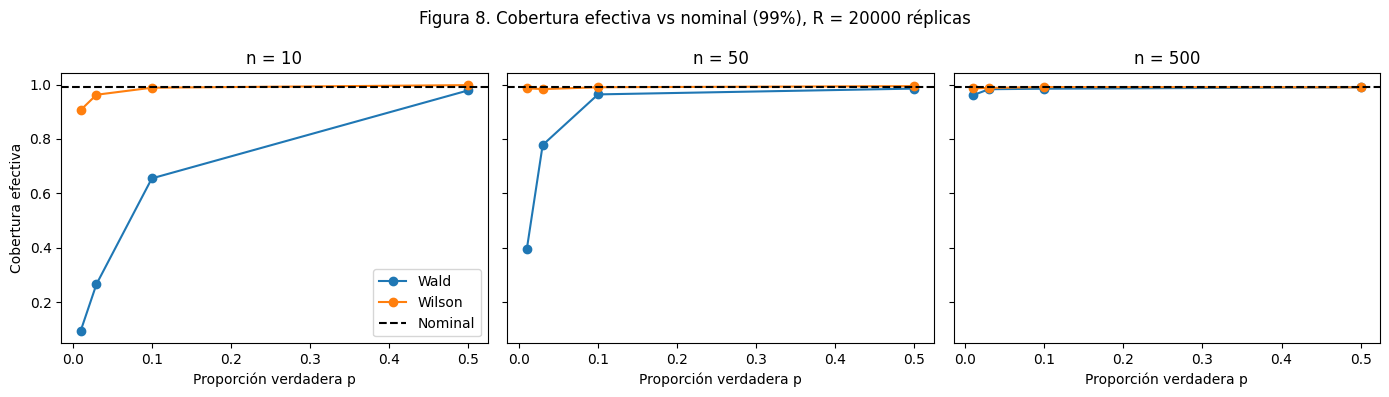

In [ ]:
# Figura 8: cobertura efectiva vs nominal
# Un panel (subgráfica) por cada tamaño de muestra n.
# sharey=True hace que todos usen el mismo eje vertical para comparar.
fig, ejes = plt.subplots(1, len(ns), figsize=(14, 4), sharey=True)

for eje, n in zip(ejes, ns):                 # recorre cada panel junto a su n
    for nombre in metodos:                   # Wald y Wilson
        # Filtramos los resultados de este n y de este método
        d = res_f4[(res_f4["n"] == n) & (res_f4["metodo"] == nombre)]
        # Dibujamos cobertura (eje y) contra p (eje x)
        eje.plot(d["p"], d["cobertura"], marker="o", label=nombre)

    # Línea punteada con la cobertura que se promete (nominal)
    eje.axhline(confianza, color="k", linestyle="--", label="Nominal")
    eje.set_title(f"n = {n}")                # título de cada panel
    eje.set_xlabel("Proporción verdadera p") # rótulo del eje x

ejes[0].set_ylabel("Cobertura efectiva")     # rótulo del eje y (solo en el primer panel)
ejes[0].legend()                             # leyenda: qué línea es cada método

# Título general de la figura, con el número que pide el enunciado
fig.suptitle(f"Figura 8. Cobertura efectiva vs nominal ({confianza:.0%}), R = {R} réplicas")
plt.tight_layout()                           # evita que se encimen los textos
plt.show()

**F.5**

F5.Tamaño de muestra necesario para la diferencia de tiempo de GPU

In [26]:
#Tamaño de muestra necesario para semiancho <= 1 ms en F3(i) y verificación
# Paso 1: Deducción teórica del tamaño de muestra n por versión
# Usamos las desviaciones estándar observadas de gpu_ms (sin caché) en A y B
sA = gpu_A.std(ddof=1)                                # DE de GPU sin caché en versión A
sB = gpu_B.std(ddof=1)                                # DE de GPU sin caché en versión B
z_crit = stats.norm.ppf(1 - alpha / 2)                # valor crítico normal para 99% (~2.5758)
semiancho_meta = 1.0                                  # semiancho máximo deseado: 1 ms

# Fórmula despejada: n >= z^2 * (sA^2 + sB^2) / E^2
n_teorico = (z_crit**2) * (sA**2 + sB**2) / (semiancho_meta**2)
n_necesario = int(np.ceil(n_teorico))                 # redondeamos hacia arriba al entero siguiente

print(f"s_A = {sA:.4f} ms | s_B = {sB:.4f} ms | z = {z_crit:.4f}")
print(f"n exacto de la fórmula = {n_teorico:.2f} -> n necesario por versión = {n_necesario}\n")

s_A = 45.6878 ms | s_B = 37.8313 ms | z = 2.5758
n exacto de la fórmula = 23345.47 -> n necesario por versión = 23346



In [27]:
# Paso 2: Verificación por simulación (tomando R = 10,000 muestras de tamaño n_necesario)
R_f5 = 10_000
semianchos_sim = np.empty(R_f5)
aciertos_sim = np.empty(R_f5, dtype=bool)
diff_real = gpu_B.mean() - gpu_A.mean()               # diferencia "verdadera" en los datos

for r in range(R_f5):
    # Remuestreamos n_necesario solicitudes sin caché de A y n_necesario de B
    mA = rng.choice(gpu_A, size=n_necesario, replace=True)
    mB = rng.choice(gpu_B, size=n_necesario, replace=True)

    # Calculamos la diferencia muestral y el semiancho del intervalo en esta simulación
    d_sim = mB.mean() - mA.mean()
    ee_sim = np.sqrt(mB.var(ddof=1) / n_necesario + mA.var(ddof=1) / n_necesario)
    t_sim = stats.t.ppf(1 - alpha / 2, df=2 * n_necesario - 2)

    semiancho = t_sim * ee_sim
    semianchos_sim[r] = semiancho
    aciertos_sim[r] = (d_sim - semiancho <= diff_real) & (diff_real <= d_sim + semiancho)

print("=== Resultados de la verificación por simulación ===")
print(f"Semiancho promedio simulado : {semianchos_sim.mean():.4f} ms (meta <= 1.0000 ms)")
print(f"Mediana del semiancho       : {np.median(semianchos_sim):.4f} ms")
print(f"% de veces con semiancho <= 1 ms: {100 * np.mean(semianchos_sim <= 1.0):.2f}%")
print(f"Cobertura efectiva          : {aciertos_sim.mean():.4f} (nominal = {confianza:.2f})")

=== Resultados de la verificación por simulación ===
Semiancho promedio simulado : 1.0000 ms (meta <= 1.0000 ms)
Mediana del semiancho       : 0.9999 ms
% de veces con semiancho <= 1 ms: 50.53%
Cobertura efectiva          : 0.9912 (nominal = 0.99)


**F.6**

F6. Validación de parámetros e intervalos con nuevos datos

In [15]:
# **F6.** Validación con solicitudes_validacion.csv (celda autocontenida)
import os
import numpy as np
import pandas as pd
from scipy import stats
from google.colab import files

# 1. Parámetros de tu grupo (C1 = 2028596201, C2 = 2035384971, S = 4063981172)
S = 2028596201 + 2035384971
tau = 180 + 10 * (S % 9)          # 230 ms
confianza = 0.99                  # porque S % 3 == 2
alpha = 1 - confianza             # 0.01

# 2. Verificar que estén ambos archivos (si falta alguno, abre el botón para subirlo)
for archivo in ["solicitudes.csv", "solicitudes_validacion.csv"]:
    if not os.path.exists(archivo):
        print(f"Por favor sube el archivo: {archivo}")
        files.upload()

# 3. Función de limpieza física (reglas de A1)
def limpiar_f6(df):
    d = df.drop_duplicates().copy()
    mask_bytes = d["tam_kb"] > 5000
    d.loc[mask_bytes, "tam_kb"] = d.loc[mask_bytes, "tam_kb"] / 1024
    d = d[d["latencia_ms"] > 0].copy()
    cache = d["cache_hit"] == 1
    d.loc[cache & d["gpu_ms"].isna(), "gpu_ms"] = 0
    falta_red = cache & d["red_ms"].isna()
    d.loc[falta_red, "red_ms"] = d.loc[falta_red, "latencia_ms"]
    d = d[~(d["red_ms"].isna() | d["gpu_ms"].isna())].copy()
    d = d[d["latencia_ms"] >= d["red_ms"] + d["gpu_ms"] - 0.02].copy()
    return d.reset_index(drop=True)

# 4. Cargar datos originales (régimen estable sin el hueco anómalo [397, 577)) y validación
df_orig = limpiar_f6(pd.read_csv("solicitudes.csv"))
df_est_f6 = df_orig[(df_orig["t_llegada_s"] < 397) | (df_orig["t_llegada_s"] >= 577)].copy()
df_val = limpiar_f6(pd.read_csv("solicitudes_validacion.csv"))

for d in (df_est_f6, df_val):
    d["viola_tau"] = (d["latencia_ms"] > tau).astype(int)
    d["reintento"] = (d["intentos"] > 1).astype(int)
    d["no_cache"] = (d["cache_hit"] == 0)

print(f"Filas régimen estable original: {len(df_est_f6)} | Filas limpias validación: {len(df_val)}\n")

# 5. Funciones para intervalos al 99% (Wilson para proporciones, Normal/Welch para medias)
def ic_wilson(x, n, a):
    p = x / n
    z = stats.norm.ppf(1 - a / 2)
    denom = 1 + z**2 / n
    centro = (p + z**2 / (2 * n)) / denom
    margen = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centro - margen, centro + margen

def comparar_media(s1, s2, nombre):
    m1, m2 = s1.mean(), s2.mean()
    sd1, sd2 = s1.std(ddof=1), s2.std(ddof=1)
    n1, n2 = len(s1), len(s2)
    z = stats.norm.ppf(1 - alpha / 2)
    ic1 = (m1 - z * sd1 / np.sqrt(n1), m1 + z * sd1 / np.sqrt(n1))
    diff = m2 - m1
    ee = np.sqrt(sd1**2 / n1 + sd2**2 / n2)
    ic_d = (diff - z * ee, diff + z * ee)
    return {
        "Parámetro": nombre,
        "Original": round(m1, 4),
        "IC 99% Original": f"[{ic1[0]:.4f}, {ic1[1]:.4f}]",
        "Validación": round(m2, 4),
        "Cambio (Val - Orig)": round(diff, 4),
        "Cambio (%)": round(100 * diff / m1, 2),
        "IC 99% Diferencia": f"[{ic_d[0]:.4f}, {ic_d[1]:.4f}]",
        "¿Cambió?": "SÍ cambió" if (ic_d[0] > 0 or ic_d[1] < 0) else "No cambió"
    }

def comparar_prop(x1, n1, x2, n2, nombre):
    p1, p2 = x1 / n1, x2 / n2
    l1, u1 = ic_wilson(x1, n1, alpha)
    l2, u2 = ic_wilson(x2, n2, alpha)
    diff = p2 - p1
    inf_d = diff - np.sqrt((p2 - l2)**2 + (u1 - p1)**2)
    sup_d = diff + np.sqrt((u2 - p2)**2 + (p1 - l1)**2)
    return {
        "Parámetro": nombre,
        "Original": round(p1, 4),
        "IC 99% Original": f"[{l1:.4f}, {u1:.4f}]",
        "Validación": round(p2, 4),
        "Cambio (Val - Orig)": round(diff, 4),
        "Cambio (%)": round(100 * diff / p1, 2),
        "IC 99% Diferencia": f"[{inf_d:.4f}, {sup_d:.4f}]",
        "¿Cambió?": "SÍ cambió" if (inf_d > 0 or sup_d < 0) else "No cambió"
    }

# 6. Comparar parámetros de Partes B, C y F
segundos_activos = sorted(set(range(0, 1200)) - set(range(397, 577)))
conteos_orig = np.floor(df_est_f6["t_llegada_s"]).astype(int).value_counts().reindex(segundos_activos, fill_value=0)
conteos_val = np.floor(df_val["t_llegada_s"]).astype(int).value_counts().reindex(range(0, 1200), fill_value=0)

filas = [
    comparar_media(conteos_orig, conteos_val, "Parte B: Tasa llegadas λ (sol/s)"),
    comparar_prop(df_est_f6["reintento"].sum(), len(df_est_f6), df_val["reintento"].sum(), len(df_val), "Parte B: P(intentos > 1)"),
    comparar_prop(df_est_f6["cache_hit"].sum(), len(df_est_f6), df_val["cache_hit"].sum(), len(df_val), "Parte C: P(cache_hit = 1)"),
    comparar_media(df_est_f6.loc[df_est_f6["no_cache"], "gpu_ms"], df_val.loc[df_val["no_cache"], "gpu_ms"], "Parte C: GPU sin caché (ms)"),
    comparar_media(df_est_f6["red_ms"], df_val["red_ms"], "Parte C: Red media (ms)"),
    comparar_media(df_est_f6["latencia_ms"], df_val["latencia_ms"], "Parte F: Latencia media (ms)"),
    comparar_prop(df_est_f6["viola_tau"].sum(), len(df_est_f6), df_val["viola_tau"].sum(), len(df_val), f"Parte F: P(latencia > {tau} ms)")
]

display(pd.DataFrame(filas))

# 7. Verificar ventaja B vs A en GPU sin caché dentro de validación
vA = df_val[(df_val["version"] == "A") & (df_val["no_cache"])]["gpu_ms"]
vB = df_val[(df_val["version"] == "B") & (df_val["no_cache"])]["gpu_ms"]
diff_AB = vB.mean() - vA.mean()
ee_AB = np.sqrt(vB.var(ddof=1)/len(vB) + vA.var(ddof=1)/len(vA))
z_99 = stats.norm.ppf(1 - alpha / 2)
print(f"B vs A en validación (GPU sin caché): A={vA.mean():.2f} ms, B={vB.mean():.2f} ms, Diff={diff_AB:.2f} ms, IC 99%=[{diff_AB - z_99*ee_AB:.2f}, {diff_AB + z_99*ee_AB:.2f}] ms")

Filas régimen estable original: 22009 | Filas limpias validación: 26069



,Parámetro,Original,IC 99% Original,Validación,Cambio (Val - Orig),Cambio (%),IC 99% Diferencia,¿Cambió?
0,Parte B: Tasa llegadas λ (sol/s),21.5775,"[21.2076, 21.9473]",21.7242,0.1467,0.68,"[-0.3598, 0.6532]",No cambió
1,Parte B: P(intentos > 1),0.1755,"[0.1690, 0.1822]",0.1741,-0.0014,-0.82,"[-0.0104, 0.0075]",No cambió
2,Parte C: P(cache_hit = 1),0.3508,"[0.3426, 0.3591]",0.3516,0.0008,0.22,"[-0.0105, 0.0120]",No cambió
3,Parte C: GPU sin caché (ms),50.3016,"[49.3932, 51.2100]",53.3551,3.0536,6.07,"[1.8034, 4.3037]",SÍ cambió
4,Parte C: Red media (ms),26.4263,"[26.3588, 26.4938]",26.4766,0.0503,0.19,"[-0.0412, 0.1418]",No cambió
5,Parte F: Latencia media (ms),63.1939,"[62.3952, 63.9927]",66.1131,2.9191,4.62,"[1.8003, 4.0380]",SÍ cambió
6,Parte F: P(latencia > 230 ms),0.0100,"[0.0085, 0.0119]",0.0124,0.0024,23.77,"[-0.0001, 0.0049]",No cambió


B vs A en validación (GPU sin caché): A=53.79 ms, B=52.92 ms, Diff=-0.86 ms, IC 99%=[-2.58, 0.85] ms
